In [3]:
#importing all the needed libraries

import sys #Hold info about the running program
import os  #It gives tools for files, folders and the system
from scipy import stats
import matplotlib.pyplot as plt #Visualisation of data
import numpy as np #Arrays of numbers
import pandas as pd #Tabulation of dat
import numpy as np
from scipy.optimize import curve_fit

In [4]:
#Reading the required file and fitting f

#A condition to read the spaced version if present
if os.path.exists("Simulated v_s observed - Sheet1.csv"):
        path = "Simulated v_s observed - Sheet1.csv"
else:
        path = "Simulated_v_s_observed_-_Sheet1.csv"        #Spaces sometimes gets changed to underscores if it got uploaded in someplace

FIRST_YEAR = 1959    #Starting data

df = pd.read_csv(path)
df.columns = ["sim", "obs"]
df["year"] = FIRST_YEAR + np.arange(len(df))

# shifting both series to start at 0 in the first year to measure relative warming
df["obs0"] = df["obs"] - df["obs"].iloc[0]
df["sim0"] = df["sim"] - df["sim"].iloc[0]

both = df.dropna(subset=["sim"])
res = both["obs0"] - both["sim0"]
rms = np.sqrt(np.mean(res**2))



years = both["year"].to_numpy()
sim0  = both["sim0"].to_numpy()      # your f = 1 simulation, starts at 0
obs0  = both["obs0"].to_numpy()

def scaled_model(x, f):
    return f * sim0                  # x is unused, but curve_fit needs it

popt, pcov = curve_fit(scaled_model, years, obs0, p0=[1.0])
f_fit, f_err = popt[0], np.sqrt(pcov[0, 0])
print(f"f = {f_fit:.2f} +/- {1.96 * f_err:.2f}")



f = 1.96 +/- 0.14


In [5]:
# n is the number of data points in the overlap period
n = len(both)

# Calculate the standard error of the slope f through the origin
residuals = both["obs0"] - f_fit * both["sim0"]
s = np.sqrt(np.sum(residuals**2) / (n - 1))
se_f = s / np.sqrt(np.sum(both["sim0"]**2))

t = stats.t.ppf(0.975, df=n - 1)              # 95% two-sided critical value
ci = (f_fit - t * se_f, f_fit + t * se_f)

print(f"f = {f_fit:.2f} +/- {t*se_f:.2f}  \n95% CI: {ci[0]:.2f} to {ci[1]:.2f}")

f = 1.96 +/- 0.14  
95% CI: 1.82 to 2.10


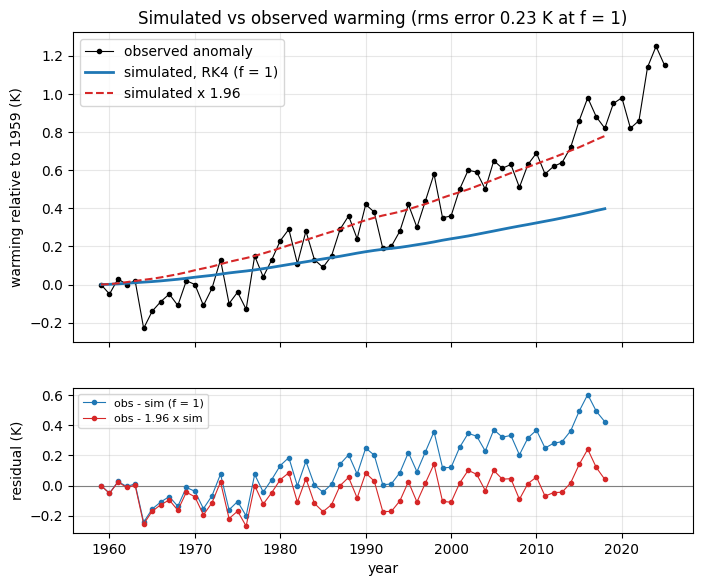

In [8]:
#Plotting the graph

# Define f using the fitted value from the previous cells
f = f_fit

%matplotlib inline
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1.4]})
ax1.plot(df.year, df.obs0, "k.-", lw=0.8, label="observed anomaly")
ax1.plot(both.year, both.sim0, color="tab:blue", lw=2, label="simulated, RK4 (f = 1)")
ax1.plot(both.year, f * both.sim0, color="tab:red", ls="--", label=f"simulated x {f:.2f}")
ax1.set_ylabel("warming relative to 1959 (K)")
ax1.set_title(f"Simulated vs observed warming (rms error {rms:.2f} K at f = 1)")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.axhline(0, color="gray", lw=0.8)
ax2.plot(both.year, res, "o-", ms=3, lw=0.8, color="tab:blue", label="obs - sim (f = 1)")
ax2.plot(both.year, both.obs0 - f * both.sim0, "o-", ms=3, lw=0.8, color="tab:red",
         label=f"obs - {f:.2f} x sim")
ax2.set_xlabel("year"); ax2.set_ylabel("residual (K)")
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

plt.show()